## LightGBM with OOF Target Encoding, Cohen's d Feature Selection, and Neyman-Pearson Threshold Optimisation




In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
import warnings
import re
warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score,
                             roc_curve, fbeta_score)
from sklearn.calibration import CalibratedClassifierCV
from sklearn.preprocessing import StandardScaler
from scipy.stats import mannwhitneyu
from lightgbm import LGBMClassifier

## Data Loading

In [2]:
try:
    original_data = pd.read_excel('May-12-Status-Contracts.xlsx')
except:
    uploaded = files.upload()
    original_data = pd.read_excel(list(uploaded.keys())[0])
data = original_data.copy()

try:
    updated_data = pd.read_excel('Extracted-New.xlsx')
except:
    uploaded = files.upload()
    updated_data = pd.read_excel(list(uploaded.keys())[0])

print(f"Original: {data.shape} | Updated: {updated_data.shape}")

Original: (22300, 38) | Updated: (25695, 48)


##  Combine Datasets

In [3]:
updated_data = updated_data.rename(columns={'Unit Brand': 'Manufacturer'})
data.drop(columns=['Product Type.1'], inplace=True, errors='ignore')
data['Borrower Type'] = 'Principal'

cols_to_drop = [
    'Address', 'Claimed Employer', 'Claimed Employer Type', 'Claimed Position',
    'Credit Info ID', 'EV Employer', 'EV Employer Type', 'EV Position',
    'Gender', 'No of Dependents'
]
updated_data = updated_data.drop(columns=cols_to_drop, errors='ignore')

original_cols = set(data.columns)
updated_cols  = set(updated_data.columns)
missing_in_updated = original_cols - updated_cols
new_in_updated     = updated_cols - original_cols

if not missing_in_updated and not new_in_updated:
    updated_data  = updated_data[data.columns]
    combined_data = pd.concat([data, updated_data], ignore_index=True)
    print(f"Merged successfully. Combined shape: {combined_data.shape}")
else:
    print("Schema mismatch — review missing/extra columns")
    print("Missing:", sorted(missing_in_updated))
    print("Extra:  ", sorted(new_in_updated))

df = combined_data.copy()
df = df.drop(columns=['Contract ID', 'Party No', 'Application No'], errors='ignore')
df.rename(columns={'Current DPD': 'Longest_DPD'}, inplace=True)


print(f"Before dedup: {df.shape}")
print(f"Duplicate rows: {df.duplicated().sum()}")
df.drop_duplicates(inplace=True)
print(f"After dedup (true dataset size): {df.shape}")


Merged successfully. Combined shape: (47995, 38)
Before dedup: (47995, 35)
Duplicate rows: 12646
After dedup (true dataset size): (35349, 35)


In [4]:
print(df.columns.tolist())

['Amount Finance', 'Longest_DPD', 'Mode of Payment', 'Contract Start Date', 'Downpayment', 'Downpayment %', 'Payment Terms', 'Asset', 'Manufacturer', 'Type of Unit', 'Price Gap', 'Loan History', 'BAP Type', 'BAP Amount', 'BAP Date', 'Interest Rate', 'Claimed Income', 'EV Income', 'BV Income', 'Employment Type', 'Claimed Tenure', 'EV Tenure', 'BV Tenure', 'DSCR', 'Age as of Contract', 'Birthday', 'Home Ownership', 'Residence Tenure', 'Citizenship', 'Dealer Name', 'Submitted ID', 'Marital Status', 'Loan Amort', 'Product Type', 'Borrower Type']


##  Preprocessing — Missing Values & Type Cleaning

In [5]:
def clean_income(x):
    if pd.isna(x): return np.nan
    x = str(x).lower().strip()
    if any(w in x for w in ['confidential','not disclosed','not provided','proof','coec','pls refer','cannot disclose']):
        return np.nan
    x = x.replace(',', '')
    x = re.sub(r'(\d+)k', r'\1000', x)
    nums = re.findall(r'\d+', x)
    if len(nums) == 1:
        value = float(nums[0])
        if 'annual' in x: value /= 12
        return value
    elif len(nums) >= 2:
        return np.mean([float(nums[0]), float(nums[1])])
    return np.nan

def clean_tenure(x):
    if pd.isna(x): return np.nan
    x = str(x).lower().strip().replace('?', '')
    if re.match(r'\d+$', x): return float(x)
    years  = re.search(r'(\d+)\s*(year|years|yr|yrs)', x)
    months = re.search(r'(\d+)\s*(month|months|mos)', x)
    y = int(years.group(1))  if years  else 0
    m = int(months.group(1)) if months else 0
    if y > 0 or m > 0: return y*12 + m
    nums = re.findall(r'\d+', x)
    return float(nums[0]) if nums else np.nan

income_cols = ['Claimed Income', 'EV Income', 'BV Income']
tenure_cols = ['Claimed Tenure', 'EV Tenure', 'BV Tenure', 'Residence Tenure']

for col in income_cols:
    mask = pd.to_numeric(df[col], errors='coerce').isnull()
    df.loc[mask, col] = df.loc[mask, col].apply(clean_income)

for col in tenure_cols:
    mask = pd.to_numeric(df[col], errors='coerce').isnull()
    df.loc[mask, col] = df.loc[mask, col].apply(clean_tenure)

df[income_cols + tenure_cols] = df[income_cols + tenure_cols].apply(pd.to_numeric, errors='coerce')

df['Longest_DPD'] = df['Longest_DPD'].fillna(0)

In [6]:

for col in ['BAP Amount', 'EV Income', 'EV Tenure']:
    df[f'{col}_missing'] = df[col].isnull().astype(int)
    df[col] = df[col].fillna(-999)

for col in ['BV Income', 'Price Gap', 'BV Tenure', 'DSCR', 'Claimed Tenure', 'Claimed Income', 'Residence Tenure']:
    df[f'{col}_missing'] = df[col].isnull().astype(int)
    df[col] = df[col].fillna(-999)

df['Loan History'] = df['Loan History'].fillna('Unknown')
df['BAP Type']     = df['BAP Type'].fillna('Unknown')
df['Citizenship']  = df['Citizenship'].fillna('Unknown')

for col in ['Type of Unit', 'Dealer Name', 'Borrower Type', 'Employment Type',
            'Home Ownership', 'Manufacturer', 'Submitted ID', 'Mode of Payment']:
    df[col] = df[col].fillna('Unknown')

df['Contract Start Date'] = df['Contract Start Date'].fillna(df['Contract Start Date'].mode()[0])
print(f"Missing values remaining: {df.isnull().sum().sum()}")

Missing values remaining: 24067


In [7]:

df['Contract_Year']  = df['Contract Start Date'].dt.year
df['Contract_Month'] = df['Contract Start Date'].dt.month
df = df.drop(columns=['Contract Start Date'])

df = df.drop(columns=['Birthday'], errors='ignore')
df = df.drop(columns=['BAP Date'],  errors='ignore')

print(f"Final shape: {df.shape}")


Final shape: (35349, 44)


In [8]:
df['Marital Status'] = df['Marital Status'].replace({
    'Separated': 'Without Partner',
    'Divorced':  'Without Partner',
    'Single':    'Single/Not Married',
    'Not Married': 'Single/Not Married'
})
df = df[~df['Marital Status'].isin(['Partner', 'Unspecified'])]

##  Feature Engineering

In [9]:
df['Target'] = df['Longest_DPD'].apply(lambda x: 0 if x <= 30 else 1)
target = 'Target'
print(f"Default rate: {df['Target'].mean():.3f}")

num_cols = df.select_dtypes(include=['int64', 'float64']).columns
df[num_cols] = df[num_cols].replace(-999, np.nan)

winsor_cols = [
    'Loan Amort', 'Claimed Income', 'Downpayment', 'Amount Finance',
    'Residence Tenure', 'BV Income', 'EV Income', 'BAP Amount',
    'Claimed Tenure', 'Interest Rate', 'Price Gap', 'DSCR'
]
for col in winsor_cols:
    if col in df.columns:
        lo = df[col].quantile(0.01)
        hi = df[col].quantile(0.99)
        df[col] = df[col].clip(lower=lo, upper=hi)

EPS = 1e-9

Default rate: 0.186


In [10]:
df['DTI']              = df['Loan Amort'] / df['Claimed Income'].replace(0, np.nan)
df['Income_Gap']       = df['Claimed Income'] - df['BV Income']
df['LTV']              = df['Amount Finance'] / (df['Amount Finance'] + df['Downpayment']).replace(0, np.nan)
df['Repayment_Stress'] = df['Loan Amort']     / df['Amount Finance'].replace(0, np.nan)

df['BAP_to_Finance']   = df['BAP Amount'] / df['Amount Finance'].replace(0, np.nan)
df['BAP_Income_Risk']  = ((df['BAP Amount'] > 200000) & (df['Income_Gap'] < 0)).astype(int)
df['BAP_Asset_Risk']   = ((df['BAP Amount'] > 200000) & (df['Price Gap'] < -50000)).astype(int)
df['Collateral_Shortfall'] = (-df['Price Gap']).clip(lower=0) / (df['Amount Finance'] + EPS)
df['Rate_x_Term']      = df['Interest Rate'] * df['Payment Terms']
df['Equity_Cushion']   = df['Downpayment'] / (df['Downpayment'] + df['Amount Finance'] + EPS)

df['Shortfall_x_Term'] = df['Collateral_Shortfall'] * df['Payment Terms']

df['Income_Gap_x_LTV'] = df['Income_Gap'] * df['LTV']
df['DTI_x_LTV']        = df['DTI'] * df['LTV']
df['DP_to_Income']     = df['Downpayment'] / df['Claimed Income'].replace(0, np.nan)
df['Age_at_Maturity'] = df['Age as of Contract'] + df['Payment Terms'] / 12

_seasoned = df['Contract_Year'].notna()  
df['High_DTI'] = (df['DTI'] > df['DTI'].quantile(0.75)).astype(int)

if 'BV Tenure' in df.columns:
    df['Tenure_Mismatch'] = (df['Claimed Tenure'] - df['BV Tenure']).abs()

if {'BV Income', 'Claimed Income'}.issubset(df.columns):
    df['Income_Inconsistency'] = (df['BV Income'] / (df['Claimed Income'] + EPS)).clip(upper=5)

_verif_cols = ['EV Income', 'BV Income', 'EV Tenure', 'BV Tenure',
               'Price Gap', 'DSCR', 'Claimed Income', 'Claimed Tenure']
df['Verification_Gaps'] = sum(df[c].isna().astype(int) for c in _verif_cols if c in df.columns)
df['High_Risk_Missing'] = (
    (df['BV Tenure_missing'] == 1) &
    (df['Claimed Tenure_missing'] == 1)
).astype(int)

df['Unverified_Income_AND_Tenure'] = (
    (df['BV Income_missing'] == 1) &
    (df['Claimed Tenure_missing'] == 1)
).astype(int)

print(f"High_Risk_Missing: {df['High_Risk_Missing'].sum()} rows")
print(f"Unverified_Income_AND_Tenure: {df['Unverified_Income_AND_Tenure'].sum()} rows")

High_Risk_Missing: 3160 rows
Unverified_Income_AND_Tenure: 5642 rows


In [11]:
_loan_history_risk = {
    'With history of Pastdue': 3, 'Poor Handling': 3,
    'Loans and other credit dealings seen on CIC': 2,
    'Existing client of JFP less than 25% Paid': 2,
    'Repeat clients of other Banks and Finances': 1,
    'Existing client of JFP 25% and above Paid': 1,
    'Existing client of JFP 50% and above Paid': 0,
    'Fully paid Good Repeat Client': 0,
}
df['Loan_History_Risk'] = df['Loan History'].map(_loan_history_risk).fillna(1)


df['High_Risk_Dealer']         = np.nan
df['Mid_Risk_Dealer']          = np.nan
df['Dealer_Risk_Tier']         = np.nan
df['GoodBorrower_RiskyDealer'] = np.nan

df['Dealer_Default_Rate'] = np.nan  
df['LoanHistory_x_DealerRisk'] = np.nan
df['Dealer_x_LowDP']           = np.nan
df['Dealer_x_Term']            = np.nan


In [12]:


df['Long_Term_Loan']  = (pd.to_numeric(df['Payment Terms'], errors='coerce') >= 37).astype(int)

_dp = pd.to_numeric(df['Downpayment %'], errors='coerce')
df['Danger_DP_Band']      = ((_dp >= 15) & (_dp < 20)).astype(int)
df['Safe_DP']             = (_dp >= 30).astype(int)
_pt = pd.to_numeric(df['Payment Terms'], errors='coerce').fillna(0)
df['LongTerm_x_DangerDP'] = ((_pt >= 37) & (_dp >= 15) & (_dp < 20)).astype(int)

if 'BAP Type' in df.columns:
    df['BAP_Adverse_Loans_Only'] = (df['BAP Type'] == 'Adverse Loans').astype(int)

_mop_risk = {
    'OTC - Bank': 4, 'OTC - Gcash (Merchant)': 3, 'ADA - Security': 3,
    'OTC': 3, 'ADA - BPI': 2, 'ADA - RCBC': 2, 'ADA - BDO': 2,
    'ADA - Metrobank': 1, 'PDC': 1, 'ADA - Eastwest': 0,
    'Salary Deduction': 0, 'OTC - Gcash (Bank Transfer)': 0,
}
df['MOP_Risk_Score'] = df['Mode of Payment'].map(_mop_risk).fillna(1)
df['High_Risk_MOP']  = df['Mode of Payment'].isin(
    ['OTC', 'ADA - Security', 'OTC - Gcash (Merchant)']
).astype(int)
df['HighRiskMOP_x_DealerTier'] = df['High_Risk_MOP'] * df['Dealer_Risk_Tier']

print(f"Feature engineering done. Shape: {df.shape}")


Feature engineering done. Shape: (35309, 83)


##  Model — OOF Encoding + Cohen's d + Neyman-Pearson Optuna

###  Train/Test Split

In [ ]:
X = df.drop(columns=['Longest_DPD', 'Target'])
y = df[target]

cat_cols = X.select_dtypes(include='object').columns.tolist()
for col in cat_cols:
    X[col] = X[col].astype('category')

X.columns = ["".join(c if c.isalnum() else "_" for c in str(col)) for col in X.columns]
cat_cols  = ["".join(c if c.isalnum() else "_" for c in str(col)) for col in cat_cols]

drop_cols = [
    'Citizenship', 'Is_Recent_Contract', 'Income_Ratio',
    'Loan_History', 'Contract_Year', 'Type_of_Unit', 'Borrower_Type',
   
    'Dealer_Default_Rate', 'LoanHistory_x_DealerRisk', 'Dealer_x_LowDP', 'Dealer_x_Term',
    'High_Risk_Dealer', 'Mid_Risk_Dealer', 'Dealer_Risk_Tier', 'GoodBorrower_RiskyDealer',
] + [c for c in X.columns if 'submit' in c.lower()]
X        = X.drop(columns=[c for c in drop_cols if c in X.columns])
cat_cols = [c for c in cat_cols if c not in drop_cols]


X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.10, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.111, random_state=42, stratify=y_train_val
)

print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")
print(f"Default rate — Train: {y_train.mean():.3f} | Val: {y_val.mean():.3f} | Test: {y_test.mean():.3f}")

Train: 28250 | Val: 3528 | Test: 3531
Default rate — Train: 0.186 | Val: 0.186 | Test: 0.186


In [14]:
print(sorted(X_train.columns.tolist()))

['Age_as_of_Contract', 'Age_at_Maturity', 'Amount_Finance', 'Asset', 'BAP_Adverse_Loans_Only', 'BAP_Amount', 'BAP_Amount_missing', 'BAP_Asset_Risk', 'BAP_Income_Risk', 'BAP_Type', 'BAP_to_Finance', 'BV_Income', 'BV_Income_missing', 'BV_Tenure', 'BV_Tenure_missing', 'Claimed_Income', 'Claimed_Income_missing', 'Claimed_Tenure', 'Claimed_Tenure_missing', 'Collateral_Shortfall', 'Contract_Month', 'DP_to_Income', 'DSCR', 'DSCR_missing', 'DTI', 'DTI_x_LTV', 'Danger_DP_Band', 'Dealer_Name', 'Downpayment', 'Downpayment__', 'EV_Income', 'EV_Income_missing', 'EV_Tenure', 'EV_Tenure_missing', 'Employment_Type', 'Equity_Cushion', 'HighRiskMOP_x_DealerTier', 'High_DTI', 'High_Risk_MOP', 'High_Risk_Missing', 'Home_Ownership', 'Income_Gap', 'Income_Gap_x_LTV', 'Income_Inconsistency', 'Interest_Rate', 'LTV', 'Loan_Amort', 'Loan_History_Risk', 'LongTerm_x_DangerDP', 'Long_Term_Loan', 'MOP_Risk_Score', 'Manufacturer', 'Marital_Status', 'Mode_of_Payment', 'Payment_Terms', 'Price_Gap', 'Price_Gap_missing'

In [15]:


smooth      = 10
global_rate = y_train.mean()


dealer_col_name = 'Dealer_Name'  

if dealer_col_name in X_train.columns:
    train_dealer = X_train[dealer_col_name].astype(str)
    dealer_stats  = y_train.groupby(train_dealer).agg(['mean', 'count'])
    dealer_smooth = (dealer_stats['mean'] * dealer_stats['count'] + global_rate * smooth) / \
                    (dealer_stats['count'] + smooth)

    def map_dealer_rate(series):
        return series.astype(str).map(dealer_smooth).fillna(global_rate)

    for df_part in (X_train, X_val, X_test):
        dr = map_dealer_rate(df_part[dealer_col_name])
        df_part['Dealer_Default_Rate']      = dr.values
        df_part['LoanHistory_x_DealerRisk'] = (df_part['Loan_History_Risk'] * dr).values
        df_part['Dealer_x_LowDP']           = (dr * (1 - df_part['Downpayment__'] / 100)).values
        df_part['Dealer_x_Term']            = (dr * df_part['Payment_Terms']).values

    print(f"Dealer default rate features added. Train mean: {X_train['Dealer_Default_Rate'].mean():.4f}")
    print(f"  Test mean: {X_test['Dealer_Default_Rate'].mean():.4f}  (should be close to train)")
else:
    print(f"WARNING: '{dealer_col_name}' column not found — skipping dealer rate features")


if dealer_col_name in X_train.columns:
    tier_high_cutoff = dealer_smooth.quantile(0.90)
    tier_mid_cutoff  = dealer_smooth.quantile(0.70)

    def map_dealer_tier(series):
        rates = series.astype(str).map(dealer_smooth).fillna(global_rate)
        tier = pd.cut(rates, bins=[-np.inf, tier_mid_cutoff, tier_high_cutoff, np.inf],
                       labels=[0, 1, 2]).astype(int)
        return tier

    dti_30_train = X_train['DTI'].quantile(0.3)  
    for df_part in (X_train, X_val, X_test):
        tier = map_dealer_tier(df_part[dealer_col_name])
        df_part['Dealer_Risk_Tier'] = tier.values
        df_part['High_Risk_Dealer'] = (tier == 2).astype(int).values
        df_part['Mid_Risk_Dealer']  = (tier == 1).astype(int).values
        df_part['GoodBorrower_RiskyDealer'] = (
            (df_part['Dealer_Risk_Tier'] >= 1) & (df_part['DTI'] < dti_30_train)
        ).astype(int).values

    print(f"Dealer risk tiers computed (train-only). "
          f"Train tier counts: {pd.Series(X_train['Dealer_Risk_Tier']).value_counts().sort_index().to_dict()}")
else:
    print(f"WARNING: '{dealer_col_name}' column not found — skipping dealer tier features")


Dealer default rate features added. Train mean: 0.1860
  Test mean: 0.1860  (should be close to train)
Dealer risk tiers computed (train-only). Train tier counts: {0: 21532, 1: 4175, 2: 2543}


###  OOF Target Encoding

In [16]:
TE_SMOOTH = 20; TE_SPLITS = 5; TE_SEED = 42
te_cols_raw = ['Dealer_Name', 'Manufacturer', 'Asset', 'Employment_Type',
               'Product_Type', 'Home_Ownership', 'Loan_History', 'BAP_Type', 'Mode_of_Payment']
te_cols = [c for c in te_cols_raw if c in X_train.columns]
print(f"Target-encoding: {te_cols}")

global_mean = y_train.mean()
kf          = KFold(n_splits=TE_SPLITS, shuffle=True, random_state=TE_SEED)
X_train = X_train.copy(); X_val = X_val.copy(); X_test = X_test.copy()

for col in te_cols:
    s_tr     = X_train[col].astype(str)
    grp      = y_train.groupby(s_tr).agg(['mean', 'count'])
    enc_full = (grp['mean'] * grp['count'] + global_mean * TE_SMOOTH) / (grp['count'] + TE_SMOOTH)
    oof = pd.Series(np.nan, index=X_train.index, dtype=float)
    for tr_idx, oof_idx in kf.split(X_train):
        s_fold = s_tr.iloc[tr_idx]; y_fold = y_train.iloc[tr_idx]
        grp_f  = y_fold.groupby(s_fold).agg(['mean', 'count'])
        enc_f  = (grp_f['mean'] * grp_f['count'] + global_mean * TE_SMOOTH) / (grp_f['count'] + TE_SMOOTH)
        oof.iloc[oof_idx] = s_tr.iloc[oof_idx].map(enc_f).values
    X_train[f'{col}_TE'] = oof.fillna(global_mean).values
    X_val[f'{col}_TE']   = X_val[col].astype(str).map(enc_full).fillna(global_mean).values
    X_test[f'{col}_TE']  = X_test[col].astype(str).map(enc_full).fillna(global_mean).values
    print(f"  {col}_TE  train={X_train[col+'_TE'].mean():.4f}  test={X_test[col+'_TE'].mean():.4f}")

drop_high_card = ['Dealer_Name', 'Asset', 'Manufacturer', 'Loan_History', 'BAP_Type']
for f in (X_train, X_val, X_test):
    f.drop(columns=[c for c in drop_high_card if c in f.columns], inplace=True)
cat_cols = [c for c in cat_cols if c not in drop_high_card]
active_cats = [c for c in cat_cols if c in X_train.columns]

X_train_enc = X_train.copy(); X_val_enc = X_val.copy(); X_test_enc = X_test.copy()
for col in active_cats:
    X_train_enc[col] = X_train_enc[col].cat.codes
    X_val_enc[col]   = X_val_enc[col].cat.codes
    X_test_enc[col]  = X_test_enc[col].cat.codes

Target-encoding: ['Dealer_Name', 'Manufacturer', 'Asset', 'Employment_Type', 'Product_Type', 'Home_Ownership', 'BAP_Type', 'Mode_of_Payment']
  Dealer_Name_TE  train=0.1850  test=0.1853
  Manufacturer_TE  train=0.1863  test=0.1867
  Asset_TE  train=0.1905  test=0.1933
  Employment_Type_TE  train=0.1860  test=0.1863
  Product_Type_TE  train=0.1859  test=0.1861
  Home_Ownership_TE  train=0.1859  test=0.1858
  BAP_Type_TE  train=0.1858  test=0.1855
  Mode_of_Payment_TE  train=0.1854  test=0.1850


In [17]:

from sklearn.experimental import enable_iterative_imputer  
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestRegressor


IMPUTE_COLS = ['Claimed_Income', 'Claimed_Tenure', 'DSCR', 'Residence_Tenure']
impute_cols_present = [c for c in IMPUTE_COLS if c in X_train_enc.columns]

if impute_cols_present:
    imputer = IterativeImputer(
        estimator=RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1),
        max_iter=5,
        random_state=42
    )

    
    X_train_enc[impute_cols_present] = imputer.fit_transform(
        X_train_enc[impute_cols_present]
    )
    
    X_val_enc[impute_cols_present]  = imputer.transform(X_val_enc[impute_cols_present])
    X_test_enc[impute_cols_present] = imputer.transform(X_test_enc[impute_cols_present])
    print(f"MissForest imputation done on: {impute_cols_present}")


train_medians = X_train_enc.median()
for df_part in (X_train_enc, X_val_enc, X_test_enc):
    for col in df_part.select_dtypes(include=['float64', 'int64']).columns:
        if df_part[col].isnull().any():
            df_part[col] = df_part[col].fillna(train_medians[col])
    for col in df_part.select_dtypes(include='object').columns:
        if df_part[col].isnull().any():
            df_part[col] = df_part[col].fillna('Unknown')

print(f"Missing after imputation — train: {X_train_enc.isnull().sum().sum()}, "
      f"val: {X_val_enc.isnull().sum().sum()}, test: {X_test_enc.isnull().sum().sum()}")

MissForest imputation done on: ['Claimed_Income', 'Claimed_Tenure', 'DSCR', 'Residence_Tenure']
Missing after imputation — train: 28250, val: 3528, test: 3531


In [18]:
print([c for c in X_train_enc.columns if 'laim' in c or 'DSC' in c or 'esid' in c])

['Claimed_Income', 'Claimed_Tenure', 'DSCR', 'Residence_Tenure', 'DSCR_missing', 'Claimed_Tenure_missing', 'Claimed_Income_missing', 'Residence_Tenure_missing']


###  Cohen's d Feature Scoring & Binary Splits

In [19]:
def rank_features_by_split_cohens_d(X_enc, y, n_thresholds=50):
    y_arr = y.values.astype(float)
    results = []
    numeric_cols = [c for c in X_enc.columns if pd.api.types.is_numeric_dtype(X_enc[c])]

    for col in numeric_cols:
        x = X_enc[col].values.astype(float)
        valid = ~np.isnan(x)
        xv, yv = x[valid], y_arr[valid]
        if len(xv) < 10:
            results.append({'Feature': col, 'Best_Threshold': None, 'Split_Cohens_d': 0.0})
            continue

        thresholds = np.percentile(xv, np.linspace(5, 95, n_thresholds))
        left       = xv[None, :] <= thresholds[:, None]       
        n_left     = left.sum(axis=1)
        n_right    = len(xv) - n_left
        valid_t    = (n_left >= 5) & (n_right >= 5)

        if not valid_t.any():
            results.append({'Feature': col, 'Best_Threshold': None, 'Split_Cohens_d': 0.0})
            continue

        sum_left   = left.dot(yv)
        mean_left  = np.where(n_left  > 0, sum_left / n_left, 0.0)
        mean_right = np.where(n_right > 0, (yv.sum() - sum_left) / n_right, 0.0)

        y2         = yv ** 2
        sum2_left  = left.dot(y2)
        var_left   = np.where(n_left  > 1, sum2_left / n_left  - mean_left  ** 2, 0.0)
        var_right  = np.where(n_right > 1, (y2.sum() - sum2_left) / n_right - mean_right ** 2, 0.0)
        pooled_std = np.sqrt((np.maximum(var_left, 0) + np.maximum(var_right, 0)) / 2)

        with np.errstate(divide='ignore', invalid='ignore'):
            d = np.where(pooled_std > 0, np.abs(mean_left - mean_right) / pooled_std, 0.0)
        d[~valid_t] = 0.0

        best_idx   = int(np.argmax(d))
        best_score = float(d[best_idx])
        results.append({
            'Feature':        col,
            'Best_Threshold': round(float(thresholds[best_idx]), 4) if best_score > 0 else None,
            'Split_Cohens_d': round(best_score, 4),
        })

    return pd.DataFrame(results).sort_values('Split_Cohens_d', ascending=False).reset_index(drop=True)

print("Running Cohen's d scoring (vectorized)...")
split_df = rank_features_by_split_cohens_d(X_train_enc, y_train)

strong_split   = split_df[split_df['Split_Cohens_d'] > 0.5]['Feature'].tolist()
moderate_split = split_df[(split_df['Split_Cohens_d'] > 0.2) & (split_df['Split_Cohens_d'] <= 0.5)]['Feature'].tolist()
print(f"Strong (d>0.5)  : {strong_split}")
print(f"Moderate (d>0.2): {moderate_split}")

cohens_d_order  = split_df['Feature'].tolist()
remaining       = [c for c in X_train_enc.columns if c not in cohens_d_order]
final_col_order = [c for c in cohens_d_order if c in X_train_enc.columns] + remaining

X_train_cd = X_train_enc[final_col_order].copy()
X_val_cd   = X_val_enc[final_col_order].copy()
X_test_cd  = X_test_enc[final_col_order].copy()

cohens_d_best = split_df.set_index('Feature')['Best_Threshold'].to_dict()
for feat in strong_split:
    if feat not in X_train_cd.columns or cohens_d_best.get(feat) is None: continue
    thresh   = cohens_d_best[feat]
    col_name = f'{feat}_cd_split'
    X_train_cd[col_name] = (X_train_cd[feat] <= thresh).astype(int)
    X_val_cd[col_name]   = (X_val_cd[feat]   <= thresh).astype(int)
    X_test_cd[col_name]  = (X_test_cd[feat]  <= thresh).astype(int)
    print(f"Binary split: {col_name} (t={thresh:.4f})")

X_train_cd = X_train_cd.loc[:, ~X_train_cd.columns.duplicated()]
X_val_cd   = X_val_cd.loc[:, ~X_val_cd.columns.duplicated()]
X_test_cd  = X_test_cd.loc[:, ~X_test_cd.columns.duplicated()]
print(f"Total features: {X_train_cd.shape[1]}")

X_train_val_cd = pd.concat([X_train_cd, X_val_cd]).reset_index(drop=True)
y_train_val_cd = pd.concat([y_train, y_val]).reset_index(drop=True)

Running Cohen's d scoring (vectorized)...
Strong (d>0.5)  : ['MOP_Risk_Score', 'Dealer_x_LowDP', 'Mode_of_Payment', 'BAP_Income_Risk', 'Dealer_Default_Rate', 'Dealer_Risk_Tier', 'High_Risk_Dealer', 'Dealer_x_Term', 'LoanHistory_x_DealerRisk']
Moderate (d>0.2): ['Dealer_Name_TE', 'Downpayment__', 'GoodBorrower_RiskyDealer', 'Equity_Cushion', 'LTV', 'Payment_Terms', 'Asset_TE', 'Repayment_Stress', 'DTI_x_LTV', 'Employment_Type_TE', 'Product_Type_TE', 'Mid_Risk_Dealer', 'Rate_x_Term', 'Manufacturer_TE', 'BAP_Adverse_Loans_Only', 'Claimed_Tenure', 'DTI', 'Collateral_Shortfall', 'Interest_Rate']
Binary split: MOP_Risk_Score_cd_split (t=3.0000)
Binary split: Dealer_x_LowDP_cd_split (t=0.2632)
Binary split: Mode_of_Payment_cd_split (t=10.0000)
Binary split: BAP_Income_Risk_cd_split (t=0.0000)
Binary split: Dealer_Default_Rate_cd_split (t=0.3081)
Binary split: Dealer_Risk_Tier_cd_split (t=1.0000)
Binary split: High_Risk_Dealer_cd_split (t=0.0000)
Binary split: Dealer_x_Term_cd_split (t=16.9276

In [20]:
redundant_cols = [
    'LoanHistory_x_DealerRisk_cd_split',
    'Dealer_x_LowDP_cd_split',
    'Dealer_Default_Rate_cd_split',
    'Dealer_x_Term_cd_split',
    'GoodBorrower_RiskyDealer_cd_split',
    'High_Risk_Dealer_cd_split',
    'HighRiskMOP_x_DealerTier_cd_split',
    'High_DTI',
    'GoodBorrower_RiskyDealer',
]

for _df in (X_train_cd, X_val_cd, X_test_cd, X_train_val_cd):
    _df.drop(columns=[c for c in redundant_cols if c in _df.columns], inplace=True)

print(f"Dropped {len(redundant_cols)} redundant features")
print(f"Features remaining: {X_train_cd.shape[1]}")

Dropped 9 redundant features
Features remaining: 81


### Neyman-Pearson Optuna (300 trials)

In [69]:
MAX_NP_FPR = 0.035

def objective(trial):
    params = {
        'n_estimators':      trial.suggest_int('n_estimators', 200, 1500),
        'max_depth':         trial.suggest_int('max_depth', 3, 12),
        'num_leaves':        trial.suggest_int('num_leaves', 20, 200),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 60),
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'subsample':         trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_alpha':         trial.suggest_float('reg_alpha', 1e-4, 1.0, log=True),
        'reg_lambda':        trial.suggest_float('reg_lambda', 1e-4, 1.0, log=True),
        'scale_pos_weight':  trial.suggest_float('scale_pos_weight', 3.0, 20.0),
    }
    model = LGBMClassifier(**params, random_state=42, verbose=-1)
    model.fit(X_train_cd, y_train, categorical_feature=active_cats)
    proba = model.predict_proba(X_val_cd)[:, 1]
    fpr_v, tpr_v, _ = roc_curve(y_val, proba)
    valid = np.where(fpr_v <= MAX_NP_FPR)[0]
    return tpr_v[valid[-1]] if len(valid) > 0 else 0.0

print(f"Neyman-Pearson Optuna (300 trials, FPR≤{MAX_NP_FPR})...")
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=300, show_progress_bar=True)

best_params = study.best_params
print(f"Best params : {best_params}")
print(f"Best recall at FPR≤{MAX_NP_FPR}: {study.best_value:.4f}")

Neyman-Pearson Optuna (300 trials, FPR≤0.035)...


  0%|          | 0/300 [00:00<?, ?it/s]

Best params : {'n_estimators': 1386, 'max_depth': 12, 'num_leaves': 184, 'min_child_samples': 6, 'learning_rate': 0.1538862143578627, 'subsample': 0.7517993141753957, 'colsample_bytree': 0.6008938631093506, 'reg_alpha': 0.00012940233398199124, 'reg_lambda': 0.00022914020156036827, 'scale_pos_weight': 19.120797456529292}
Best recall at FPR≤0.035: 0.7180


###  Final Model + Results(80/10/10 split)

In [70]:
MAX_NP_FPR = 0.035

best_params = {
    'n_estimators': 1386,
    'max_depth': 12,
    'num_leaves': 184,
    'min_child_samples': 6,
    'learning_rate': 0.1538862143578627,
    'subsample': 0.7517993141753957,
    'colsample_bytree': 0.6008938631093506,
    'reg_alpha': 0.00012940233398199124,
    'reg_lambda': 0.00022914020156036827,
    'scale_pos_weight': 19.120797456529292,
}

print(f"Best params : {best_params}")
print(f"Best recall at FPR<=0.035: 0.7180")

Best params : {'n_estimators': 1386, 'max_depth': 12, 'num_leaves': 184, 'min_child_samples': 6, 'learning_rate': 0.1538862143578627, 'subsample': 0.7517993141753957, 'colsample_bytree': 0.6008938631093506, 'reg_alpha': 0.00012940233398199124, 'reg_lambda': 0.00022914020156036827, 'scale_pos_weight': 19.120797456529292}
Best recall at FPR<=0.035: 0.7180


Threshold selected on validation set (FPR<=0.035): 0.3643

              precision    recall  f1-score   support

  No Default       0.96      0.97      0.96      2875
     Default       0.85      0.81      0.83       656

    accuracy                           0.94      3531
   macro avg       0.90      0.89      0.90      3531
weighted avg       0.94      0.94      0.94      3531

Test  →  TN: 2782  FP: 93  FN: 125  TP: 531
FN Rate: 0.191  |  FP Rate: 0.032  |  AUC: 0.9224


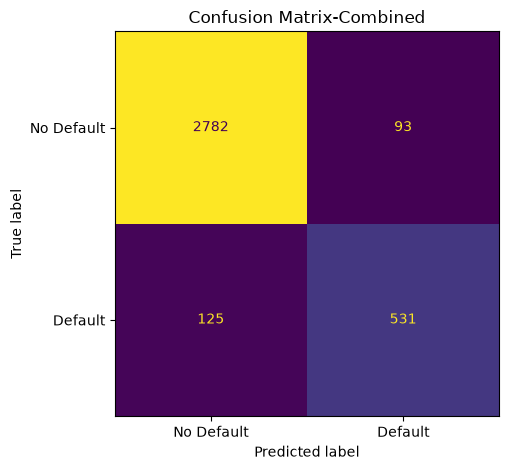

In [71]:

thresh_base  = LGBMClassifier(**best_params,
    random_state=42,
    verbose=-1, deterministic=True,
    force_row_wise=True)
thresh_model = CalibratedClassifierCV(estimator=thresh_base, method='isotonic', cv=5)
thresh_model.fit(X_train_cd, y_train, categorical_feature=active_cats)

val_proba = thresh_model.predict_proba(X_val_cd)[:, 1]
fpr_v, tpr_v, thresholds_v = roc_curve(y_val, val_proba)
valid_idx_v = np.where(fpr_v <= MAX_NP_FPR)[0]
best_thresh = thresholds_v[valid_idx_v[-1]] if len(valid_idx_v) > 0 else 0.5
print(f"Threshold selected on validation set (FPR<={MAX_NP_FPR}): {best_thresh:.4f}")


base_model  = LGBMClassifier(**best_params,
    random_state=42,
    verbose=-1, deterministic=True,
    force_row_wise=True)
final_model = CalibratedClassifierCV(estimator=base_model, method='isotonic', cv=5)
final_model.fit(X_train_val_cd, y_train_val_cd, categorical_feature=active_cats)

test_proba = final_model.predict_proba(X_test_cd)[:, 1]
test_auc   = roc_auc_score(y_test, test_proba)

y_pred = (test_proba >= best_thresh).astype(int)

print("\n" + classification_report(y_test, y_pred, target_names=['No Default', 'Default']))

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
fn_rate = fn / (fn + tp) if (fn + tp) else 0.0
fp_rate = fp / (fp + tn) if (fp + tn) else 0.0

print(f"Test  →  TN: {tn}  FP: {fp}  FN: {fn}  TP: {tp}")
print(f"FN Rate: {fn_rate:.3f}  |  FP Rate: {fp_rate:.3f}  |  AUC: {test_auc:.4f}")

disp = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=['No Default', 'Default'])
disp.plot(colorbar=False)
plt.title(f"Confusion Matrix-Combined")
plt.tight_layout()
plt.show()

###  Feature Importances

Top 20 feature importances:
           Feature  Importance
          Asset_TE       11016
              DSCR        9119
        Loan_Amort        7960
       Downpayment        7916
    Claimed_Tenure        7576
   Manufacturer_TE        7537
  Residence_Tenure        7427
       Rate_x_Term        7387
     Interest_Rate        7246
    Amount_Finance        7230
  Repayment_Stress        7133
    Claimed_Income        6933
Age_as_of_Contract        6336
Mode_of_Payment_TE        6071
    Dealer_Name_TE        5924
    Contract_Month        5319
 Home_Ownership_TE        5313
Employment_Type_TE        5124
   Product_Type_TE        4935
   Age_at_Maturity        4889


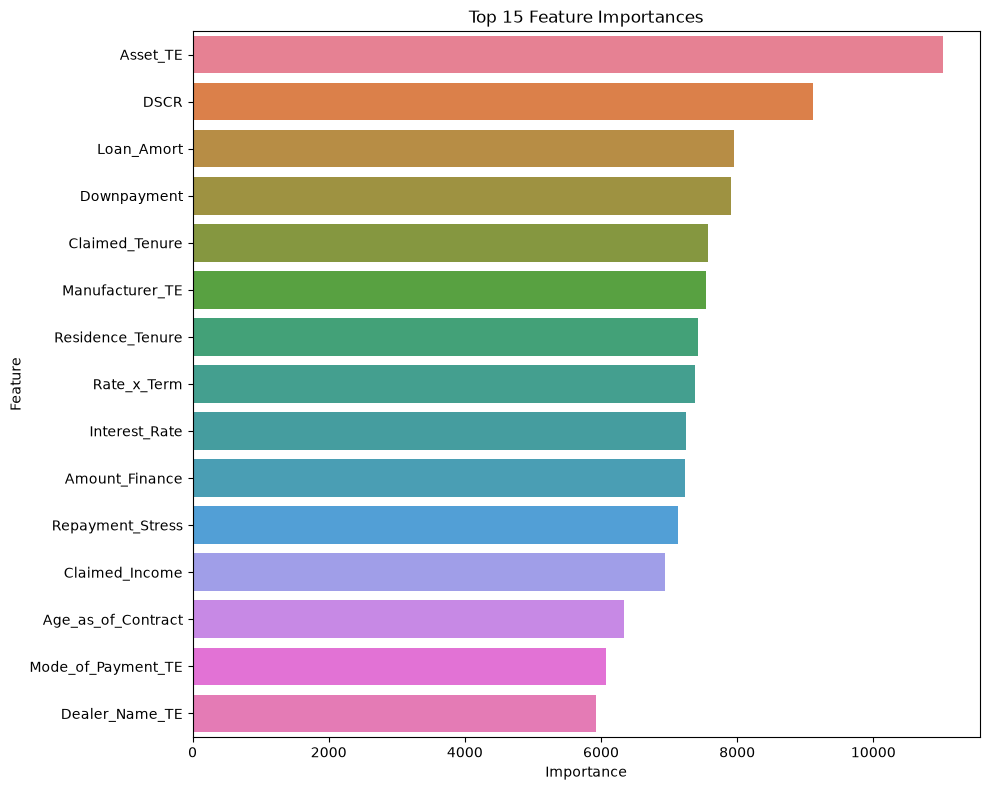

In [72]:
importance_df = (
    pd.DataFrame({'Feature': X_train_val_cd.columns,
                  'Importance': final_model.calibrated_classifiers_[0].estimator.feature_importances_})
    .sort_values('Importance', ascending=False)
)
importance_df = importance_df[importance_df['Importance'] > 0]
print("Top 20 feature importances:")
print(importance_df.head(20).to_string(index=False))

plt.figure(figsize=(10, 8))
sns.barplot(data=importance_df.head(15), x='Importance', y='Feature', hue='Feature', legend=False)
plt.title("Top 15 Feature Importances")
plt.tight_layout()
plt.show()

###  Error Profiling

In [73]:
df_eval = X_test_cd.copy()
df_eval['y_true'] = y_test.values
df_eval['y_pred'] = y_pred

TP_df = df_eval[(df_eval['y_true']==1) & (df_eval['y_pred']==1)]
FN_df = df_eval[(df_eval['y_true']==1) & (df_eval['y_pred']==0)]
TN_df = df_eval[(df_eval['y_true']==0) & (df_eval['y_pred']==0)]
FP_df = df_eval[(df_eval['y_true']==0) & (df_eval['y_pred']==1)]
print(f"TP: {len(TP_df)} | FN: {len(FN_df)} | TN: {len(TN_df)} | FP: {len(FP_df)}")

def run_mannwhitney(g1, g2, n1, n2):
    results = []
    for col in X_test_cd.columns:
        if not pd.api.types.is_numeric_dtype(df_eval[col]): continue
        a, b = g1[col].dropna(), g2[col].dropna()
        if len(a) < 5 or len(b) < 5: continue
        _, pval = mannwhitneyu(a, b, alternative='two-sided')
        if pval < 0.05:
            results.append({'Feature': col, f'{n1}_Median': round(a.median(),4),
                            f'{n2}_Median': round(b.median(),4), 'P_Value': round(pval,5)})
    return pd.DataFrame(results).sort_values('P_Value').reset_index(drop=True) if results else pd.DataFrame()

print("\n[1] TP vs FN — what separates caught defaults from missed ones:")
tp_fn = run_mannwhitney(TP_df, FN_df, 'TP', 'FN')
if not tp_fn.empty: print(tp_fn.head(10).to_string(index=False))

print("\n[2] TN vs FP — what separates correct approvals from false alarms:")
tn_fp = run_mannwhitney(TN_df, FP_df, 'TN', 'FP')
if not tn_fp.empty: print(tn_fp.head(10).to_string(index=False))

TP: 531 | FN: 125 | TN: 2782 | FP: 93

[1] TP vs FN — what separates caught defaults from missed ones:
                     Feature  TP_Median  FN_Median  P_Value
           High_Risk_Missing     0.0000     0.0000  0.00078
    Residence_Tenure_missing     0.0000     0.0000  0.00122
           Verification_Gaps     6.0000     6.0000  0.00326
         LongTerm_x_DangerDP     0.0000     0.0000  0.00357
              Danger_DP_Band     0.0000     0.0000  0.00357
Unverified_Income_AND_Tenure     0.0000     0.0000  0.00908
          Age_as_of_Contract    34.0000    36.0000  0.01103
              Dealer_x_LowDP     0.1349     0.1264  0.01180
            Dealer_Risk_Tier     0.0000     0.0000  0.01218
                    Asset_TE     0.2031     0.1942  0.01631

[2] TN vs FP — what separates correct approvals from false alarms:
                  Feature  TN_Median  FP_Median  P_Value
           Dealer_x_LowDP     0.1180     0.1608      0.0
      Dealer_Default_Rate     0.1686     0.2119      0.

###  SHAP Analysis


── Global SHAP Summary ──


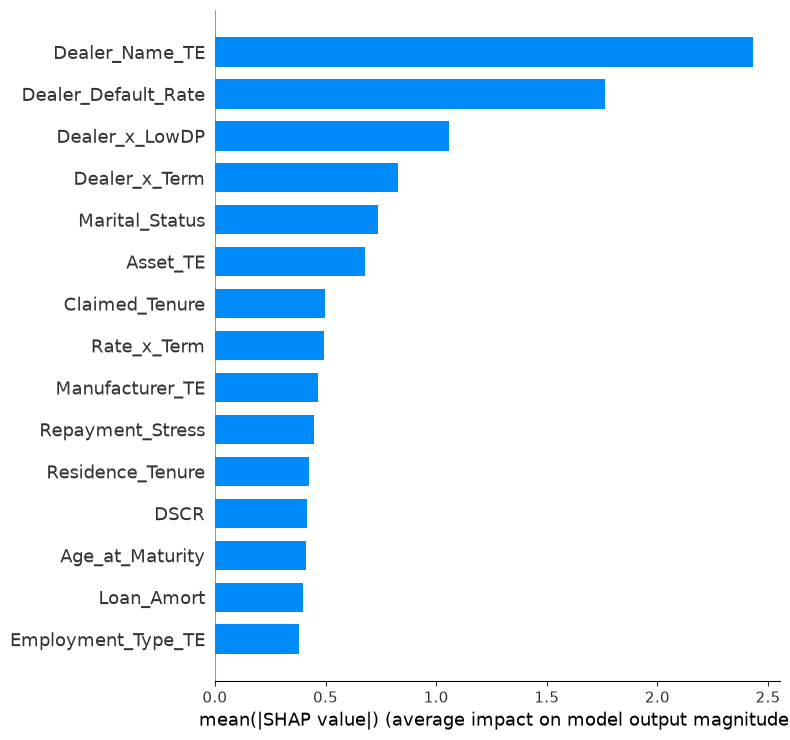

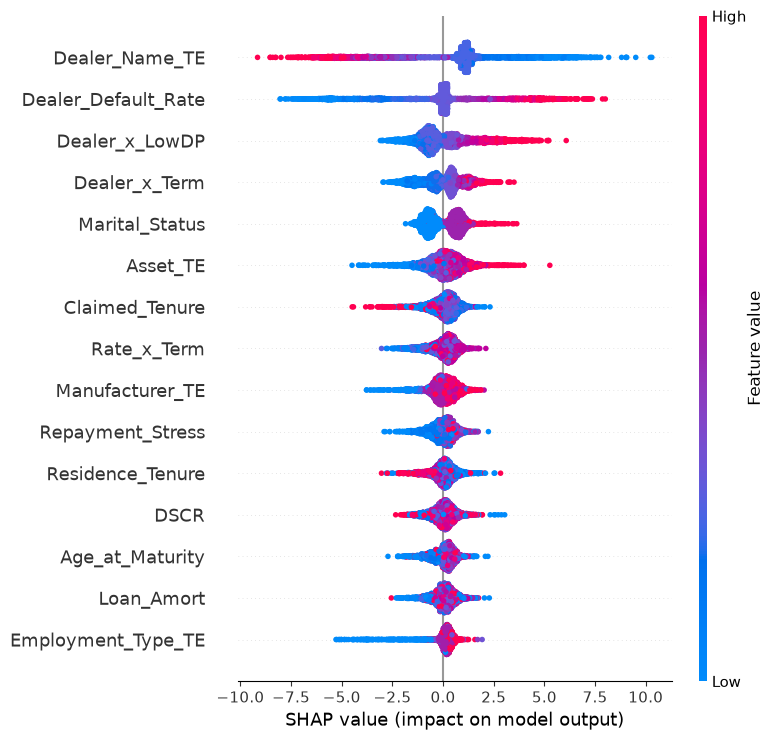

In [74]:
import shap

lgbm_base = final_model.calibrated_classifiers_[0].estimator
explainer   = shap.TreeExplainer(lgbm_base)
shap_values = explainer.shap_values(X_test_cd)
sv = shap_values[1] if isinstance(shap_values, list) else shap_values

print("── Global SHAP Summary ──")
shap.summary_plot(sv, X_test_cd, plot_type='bar', max_display=15, show=True)
shap.summary_plot(sv, X_test_cd, max_display=15, show=True)

── Top features driving MISSED defaults (FN) ──
            Feature  FN_mean_SHAP  TP_mean_SHAP
     Dealer_Name_TE      2.572307      2.766985
Dealer_Default_Rate      1.618242      2.159858
     Dealer_x_LowDP      1.024936      1.365191
      Dealer_x_Term      0.811940      0.909365
     Marital_Status      0.698453      0.818847
           Asset_TE      0.667907      0.899546
        Rate_x_Term      0.449195      0.588343
    Manufacturer_TE      0.437956      0.531447
   Repayment_Stress      0.423301      0.487876
   Residence_Tenure      0.417293      0.601640
               DSCR      0.407457      0.569526
    Age_at_Maturity      0.402595      0.498819
     Claimed_Tenure      0.376393      0.598857
 Employment_Type_TE      0.374502      0.378357
     Claimed_Income      0.357637      0.485131


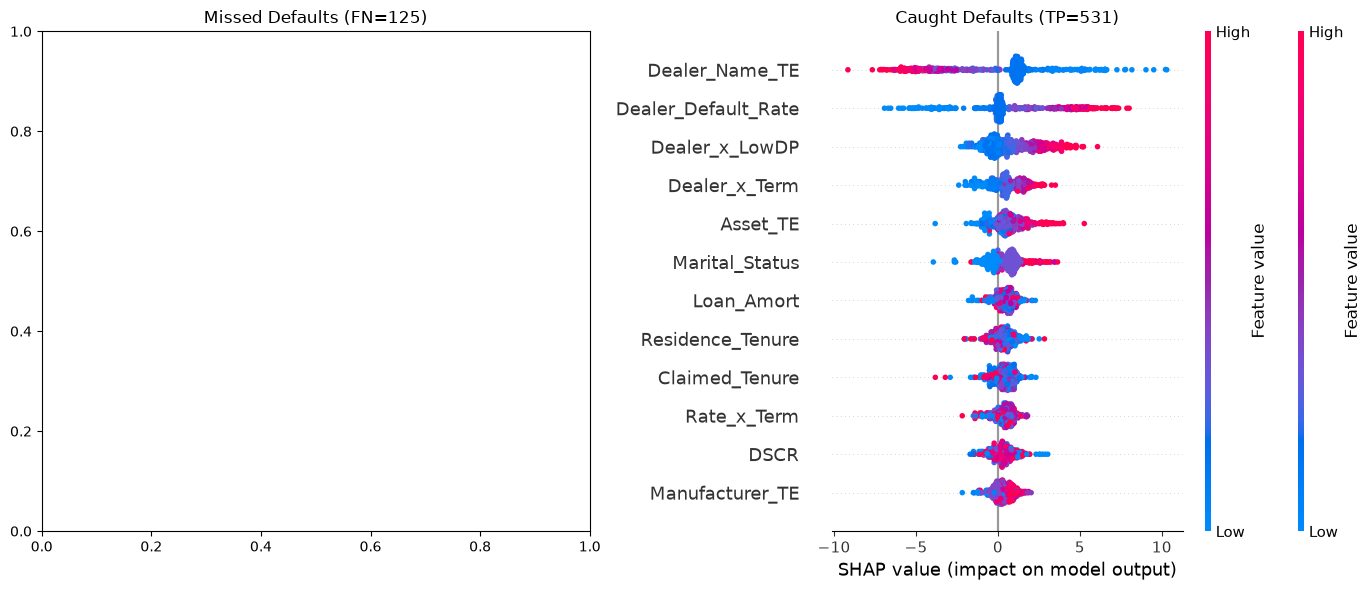


── Features pushing FN cases toward LOW RISK (negative SHAP) ──
                 Feature  Avg_negative_push
          Dealer_Name_TE          -0.425338
       Verification_Gaps          -0.111561
             Downpayment          -0.098370
                    DSCR          -0.084703
               BV_Income          -0.076652
        Repayment_Stress          -0.066168
Residence_Tenure_missing          -0.061330
LoanHistory_x_DealerRisk          -0.058149
       Home_Ownership_TE          -0.041373
          Amount_Finance          -0.034073


In [75]:

fn_mask = (y_test.values == 1) & (y_pred == 0)
tp_mask = (y_test.values == 1) & (y_pred == 1)

sv_fn = sv[fn_mask]   
sv_tp = sv[tp_mask]  

fn_mean_shap = pd.DataFrame({
    'Feature':       X_test_cd.columns,
    'FN_mean_SHAP':  np.abs(sv_fn).mean(axis=0),
    'TP_mean_SHAP':  np.abs(sv_tp).mean(axis=0),
}).sort_values('FN_mean_SHAP', ascending=False)

print("── Top features driving MISSED defaults (FN) ──")
print(fn_mean_shap.head(15).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
shap.summary_plot(sv_fn, X_test_cd[fn_mask], max_display=12,
                  show=False, plot_size=None)
axes[0].set_title(f'Missed Defaults (FN={fn_mask.sum()})')
shap.summary_plot(sv_tp, X_test_cd[tp_mask], max_display=12,
                  show=False, plot_size=None)
axes[1].set_title(f'Caught Defaults (TP={tp_mask.sum()})')
plt.tight_layout()
plt.show()


print("\n── Features pushing FN cases toward LOW RISK (negative SHAP) ──")
fn_neg = pd.DataFrame({
    'Feature': X_test_cd.columns,
    'Avg_negative_push': sv_fn.mean(axis=0)
}).sort_values('Avg_negative_push').head(10)
print(fn_neg.to_string(index=False))

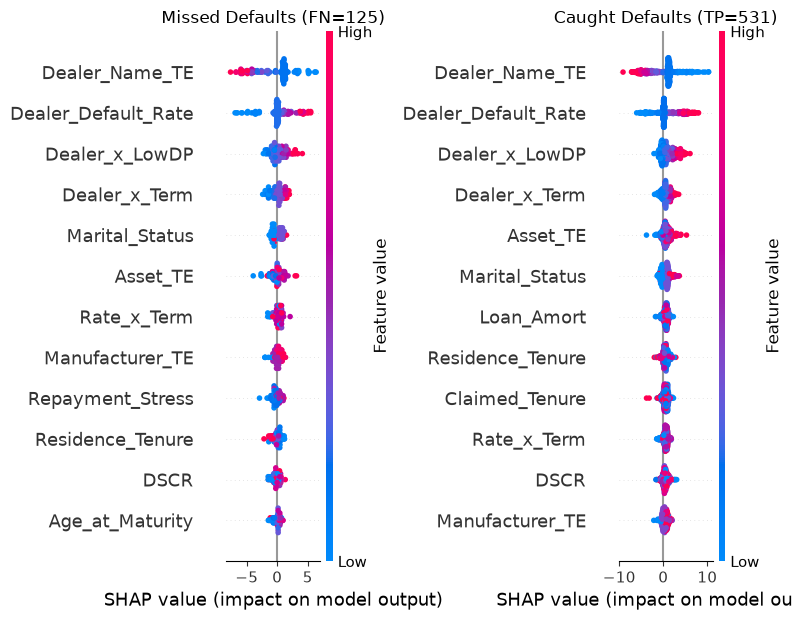

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

plt.sca(axes[0])
shap.summary_plot(sv_fn, X_test_cd[fn_mask], max_display=12,
                  show=False, plot_type='dot')
axes[0].set_title(f'Missed Defaults (FN={fn_mask.sum()})')

plt.sca(axes[1])
shap.summary_plot(sv_tp, X_test_cd[tp_mask], max_display=12,
                  show=False, plot_type='dot')
axes[1].set_title(f'Caught Defaults (TP={tp_mask.sum()})')

plt.tight_layout()
plt.show()